# Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Circle

# CONFIGURATION

In [3]:
FPS = 24
DURATION = 6
TOTAL_FRAMES = FPS * DURATION

OUTPUT_FILE = (
    r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering"
    r"\Neutron Flux Presentation\ex_core_detector_evolution.gif"
)

# Variables and Functions

In [10]:

N = 350

PELLET_RADIUS = 1.5  # metres
DETECTOR_VISION_RADIUS = 1.3  # metres

x = np.linspace(-PELLET_RADIUS, PELLET_RADIUS, N)
X, Y = np.meshgrid(x, x)
R = np.sqrt(X**2 + Y**2)

inside = R <= PELLET_RADIUS
dx = x[1] - x[0]
cell_area = dx**2

# ============================================================
# EVOLVING POWER-DENSITY PROFILE
# ============================================================
def power_density(t):
    TAU = 100
    a = 1.0 - np.exp(-t / TAU)

    # Initial central peak (characteristic width in metres)
    centre = np.exp(-(R / 0.31)**2)

    # Narrow, strong peripheral peak
    edge_band = np.exp(-((R - 1.40) / 0.10)**2)
    later = 0.15 + 100.0 * edge_band

    raw = (1.0 - a) * centre + a * later
    raw = np.where(inside, raw, 0.0)
    raw /= np.sum(raw) * cell_area

    return np.where(inside, raw, np.nan)


# ============================================================
# SCHEMATIC EX-CORE DETECTOR RESPONSE
# ============================================================
# This weighting function gives greater importance to
# peripheral regions. It is illustrative, NOT a real reactor's
# calculated neutron-transport response function.
#
# A real response depends on detector position, core geometry,
# shielding, neutron energy spectrum and neutron transport.

detector_weight = np.zeros_like(R)
detector_weight[inside] = (
    0.2 + 0.8 * (R[inside] / PELLET_RADIUS)**3
)


def detector_response(t):
    """
    Weighted spatial integral of the power-density profile.

    Expressed relative to the initial detector response.
    """

    profile = np.nan_to_num(power_density(t), nan=0.0)

    response = np.sum(
        profile * detector_weight
    ) * cell_area

    initial_profile = np.nan_to_num(
        power_density(0.0), nan=0.0
    )

    initial_response = np.sum(
        initial_profile * detector_weight
    ) * cell_area

    return 100.0 * response / initial_response

# Animtation

Saving animation to:
C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\Neutron Flux Presentation\ex_core_detector_evolution.gif
Animation saved successfully.


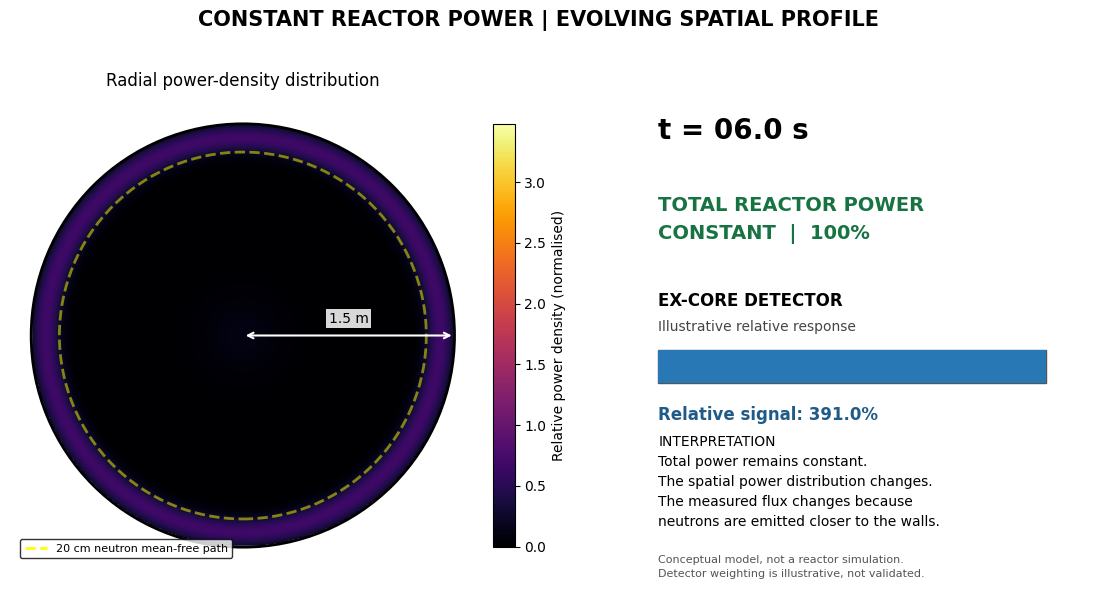

In [11]:
# ============================================================
# FIGURE: WHITE BACKGROUND, BLACK TEXT
# ============================================================
fig = plt.figure(
    figsize=(12, 7),
    facecolor="white"
)

gs = fig.add_gridspec(
    1, 2,
    width_ratios=[1.15, 1.0],
    left=0.06,
    right=0.96,
    top=0.84,
    bottom=0.13,
    wspace=0.28
)

ax = fig.add_subplot(gs[0, 0])
info = fig.add_subplot(gs[0, 1])

ax.set_facecolor("white")
info.set_facecolor("white")

fig.suptitle(
    "CONSTANT REACTOR POWER | EVOLVING SPATIAL PROFILE",
    color="black",
    fontsize=15,
    fontweight="bold",
    y=0.95
)


# ============================================================
# HEAT MAP — FULL CIRCULAR CORE
# ============================================================

from matplotlib.lines import Line2D

initial_profile = np.nan_to_num(
    power_density(0.0), nan=0.0
)

# Fixed colour scale based on the largest value over the animation
V_MAX = max(
    np.nanmax(power_density(t))
    for t in np.linspace(0, DURATION, 100)
) * 1.05

# Make the outside of the circular core transparent/white.
cmap = plt.get_cmap("inferno").copy()
cmap.set_bad("white")

image = ax.imshow(
    power_density(0.0),
    extent=[
        -PELLET_RADIUS, PELLET_RADIUS,
        -PELLET_RADIUS, PELLET_RADIUS
    ],
    origin="lower",
    cmap=cmap,
    interpolation="bilinear",
    vmin=0,
    vmax=V_MAX
)

# Outer reactor core boundary: radius 1.5 m
ax.add_patch(
    Circle(
        (0, 0),
        PELLET_RADIUS,
        fill=False,
        edgecolor="black",
        linewidth=2
    )
)

# Inner boundary: 20 cm inward from the core edge
ax.add_patch(
    Circle(
        (0, 0),
        DETECTOR_VISION_RADIUS,
        fill=False,
        edgecolor="yellow",
        linewidth=2,
        alpha = 0.5,
        linestyle="--"
    )
)

# Legend for the red dashed boundary
legend_handles = [
    Line2D(
        [0], [0],
        color="yellow",
        linestyle="--",
        linewidth=2,
        label="20 cm neutron mean-free path"
    )
]

ax.legend(
    handles=legend_handles,
    loc="lower left",
    bbox_to_anchor=(0.01, 0.01),
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="black",
    labelcolor="black"
)

# Show the complete core and a small margin around it
ax.set_xlim(-1.65, 1.65)
ax.set_ylim(-1.65, 1.65)
ax.set_aspect("equal")

ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(
    "Radial power-density distribution",
    color="black",
    fontsize=12,
    pad=12
)

# Fixed colour scale throughout the animation
colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.035,
    shrink=0.85
)

colorbar.set_label(
    "Relative power density (normalised)",
    color="black",
    fontsize=10
)

colorbar.ax.tick_params(colors="black")
colorbar.outline.set_edgecolor("black")

# Radius dimension: centre to the outer core boundary
ax.annotate(
    "",
    xy=(PELLET_RADIUS, 0),
    xytext=(0, 0),
    arrowprops=dict(
        arrowstyle="<->",
        color="white",
        linewidth=1.5
    )
)

ax.text(
    PELLET_RADIUS / 2,
    0.07,
    "1.5 m",
    color="black",
    fontsize=10,
    ha="center",
    va="bottom",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.85,
        pad=2
    )
)


# ============================================================
# INFORMATION PANEL
# ============================================================
info.set_xlim(0, 1)
info.set_ylim(0, 1)
info.axis("off")

time_text = info.text(
    0.02, 0.94,
    "t = 0.0 s",
    color="black",
    fontsize=20,
    fontweight="bold",
    va="top"
)

info.text(
    0.02, 0.78,
    "TOTAL REACTOR POWER\nCONSTANT  |  100%",
    color="#187343",
    fontsize=14,
    fontweight="bold",
    linespacing=1.6,
    va="top"
)

info.text(
    0.02, 0.56,
    "EX-CORE DETECTOR",
    color="black",
    fontsize=12,
    fontweight="bold"
)

info.text(
    0.02, 0.51,
    "Illustrative relative response",
    color="#444444",
    fontsize=10
)

# Detector response bar
bar_x = 0.02
bar_y = 0.405
bar_width = 0.88
bar_height = 0.065

info.add_patch(
    plt.Rectangle(
        (bar_x, bar_y),
        bar_width,
        bar_height,
        facecolor="#e8e8e8",
        edgecolor="#555555",
        linewidth=1
    )
)

signal_bar = plt.Rectangle(
    (bar_x, bar_y),
    bar_width,
    bar_height,
    facecolor="#2878b5",
    edgecolor="none"
)

info.add_patch(signal_bar)

signal_text = info.text(
    0.02, 0.33,
    "Relative signal: 100%",
    color="#205b87",
    fontsize=12,
    fontweight="bold"
)

info.text(
    0.02, 0.3,
    "INTERPRETATION\n"
    "Total power remains constant.\n"
    "The spatial power distribution changes.\n"
    "The measured flux changes because\n"
    "neutrons are emitted closer to the walls.",
    color="black",
    fontsize=10,
    linespacing=1.55,
    va="top"
)

info.text(
    0.02, 0.015,
    "Conceptual model, not a reactor simulation.\n"
    "Detector weighting is illustrative, not validated.",
    color="#555555",
    fontsize=8,
    linespacing=1.4
)


# ============================================================
# ANIMATION UPDATE
# ============================================================
def update(frame):
    t = frame / FPS

    # Update heat map
    image.set_data(power_density(t))

    # Update time display
    time_text.set_text(f"t = {t:04.1f} s")

    # Calculate response from the evolving spatial profile
    response = detector_response(t)

    # Scale bar relative to the initial signal.
    # Clip only the displayed bar width if it exceeds the
    # available space; the printed percentage remains actual.
    displayed_fraction = min(response / 100.0, 1.0)

    signal_bar.set_width(
        bar_width * displayed_fraction
    )

    signal_text.set_text(
        f"Relative signal: {response:.1f}%"
    )

    return image, time_text, signal_bar, signal_text


animation = FuncAnimation(
    fig,
    update,
    frames=TOTAL_FRAMES,
    interval=1000 / FPS,
    blit=True
)


# ============================================================
# SAVE GIF
# ============================================================
print(f"Saving animation to:\n{OUTPUT_FILE}")

animation.save(
    OUTPUT_FILE,
    writer=PillowWriter(fps=FPS)
)

print("Animation saved successfully.")

plt.show()
